In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import os

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [3]:
file = 'data-week-3.csv'
urllib.request.urlretrieve(data,file)
print("Download complete")

Download complete


In [4]:
if os.path.exists('data-week-3.csv'):
    print("File exists")

    df = pd.read_csv("data-week-3.csv")
    print("Shape of dataset :",df.shape)
    display(df.head())
else:
    print("Download failed, file not found")

File exists
Shape of dataset : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.columns = df.columns.str.lower().str.replace(' ','_')
categorical_col = list(df.dtypes[df.dtypes == 'object'].index)
for col in categorical_col:
    df[col] = df[col].str.lower().str.replace(' ','_')

In [6]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   object 
 4   dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   object 
 7   multiplelines     7043 non-null   object 
 8   internetservice   7043 non-null   object 
 9   onlinesecurity    7043 non-null   object 
 10  onlinebackup      7043 non-null   object 
 11  deviceprotection  7043 non-null   object 
 12  techsupport       7043 non-null   object 
 13  streamingtv       7043 non-null   object 
 14  streamingmovies   7043 non-null   object 
 15  contract          7043 non-null   object 
 16  paperlessbilling  7043 non-null   object 


In [8]:
df.isna().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [9]:
tc = pd.to_numeric(df['totalcharges'],errors='coerce')
tc

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: totalcharges, Length: 7043, dtype: float64

In [10]:
tc.isna().sum()

np.int64(11)

In [11]:
df[tc.isna()][['customerid','totalcharges']]

,customerid,totalcharges
488,4472-lvygi,_
753,3115-czmzd,_
936,5709-lvoeq,_
1082,4367-nuyao,_
1340,1371-dwpaz,_
3331,7644-omvmy,_
3826,3213-vvolg,_
4380,2520-sgtta,_
5218,2923-arzlg,_
6670,4075-wkniu,_


In [12]:
df['totalcharges'] = pd.to_numeric(df['totalcharges'],errors='coerce')
df['totalcharges'] = df.totalcharges.fillna(0)

**Encoding the target variable**

In [13]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: object

In [14]:
df.churn = (df.churn == 'yes').astype(int)

**Setting up the validation framework**

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
df_full_train,df_test = train_test_split(df,test_size=0.2,random_state=42)
df_train,df_val = train_test_split(df_full_train,test_size=0.25,random_state=42)

In [17]:
len(df_train),len(df_test),len(df_val)

(4225, 1409, 1409)

In [18]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [19]:
y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test = df_test['churn'].values

df_train = df_train.drop('churn',axis = 1)
df_val = df_val.drop('churn',axis = 1)
df_test = df_test.drop('churn',axis = 1)

In [20]:
df_full_train.churn.value_counts()

churn
0    4138
1    1496
Name: count, dtype: int64

In [21]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.734469
1    0.265531
Name: proportion, dtype: float64

In [22]:
global_mean = df_full_train.churn.mean()
round(global_mean,3)

np.float64(0.266)

In [23]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
               'phoneservice', 'multiplelines', 'internetservice',
               'onlinesecurity', 'onlinebackup', 'deviceprotection',
               'techsupport', 'streamingtv', 'streamingmovies',
               'contract', 'paperlessbilling', 'paymentmethod']
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [24]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

**Feature importance Churn rate and risk ratio**

In [25]:
female_mean = df_full_train[df_full_train.gender == 'female'].churn.mean()
print(f'Gender - >Female : {female_mean:.2f}')
male_mean = df_full_train[df_full_train.gender == 'male'].churn.mean()
print(f'Gender -> Male : {male_mean : .2f}')

Gender - >Female : 0.27
Gender -> Male :  0.26


In [26]:
female_mean / global_mean

np.float64(1.0199984815715346)

In [27]:
male_mean / global_mean

np.float64(0.9809713097066141)

In [28]:
df_full_train.partner.value_counts()

partner
no     2904
yes    2730
Name: count, dtype: int64

In [29]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_partner

np.float64(0.20073260073260074)

In [30]:
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()
churn_no_partner

np.float64(0.32644628099173556)

Risk ratio

In [31]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean','count'])
    df_group['diff'] = df_group['mean'] - global_mean
    df_group['risk'] = df_group['mean'] / global_mean
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.270841,2747,0.005310,1.019998
male,0.260478,2887,-0.005053,0.980971




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.237098,4728,-0.028433,0.892922
1,0.413907,906,0.148377,1.558793




partner


,mean,count,diff,risk
partner,,,,
no,0.326446,2904,0.060916,1.229411
yes,0.200733,2730,-0.064798,0.755968




dependents


,mean,count,diff,risk
dependents,,,,
no,0.312326,3951,0.046795,1.176233
yes,0.155674,1683,-0.109856,0.586276




phoneservice


,mean,count,diff,risk
phoneservice,,,,
no,0.253623,552,-0.011908,0.955156
yes,0.266824,5082,0.001293,1.004871




multiplelines


,mean,count,diff,risk
multiplelines,,,,
no,0.251397,2685,-0.014134,0.946771
no_phone_service,0.253623,552,-0.011908,0.955156
yes,0.284105,2397,0.018574,1.069952




internetservice


,mean,count,diff,risk
internetservice,,,,
dsl,0.191851,1939,-0.073679,0.722521
fiber_optic,0.415558,2481,0.150028,1.565010
no,0.076606,1214,-0.188924,0.288502




onlinesecurity


,mean,count,diff,risk
onlinesecurity,,,,
no,0.416014,2810,0.150484,1.566727
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.145342,1610,-0.120189,0.547363




onlinebackup


,mean,count,diff,risk
onlinebackup,,,,
no,0.398693,2448,0.133162,1.501494
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.216531,1972,-0.048999,0.815467




deviceprotection


,mean,count,diff,risk
deviceprotection,,,,
no,0.387706,2489,0.122175,1.460117
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.226825,1931,-0.038705,0.854234




techsupport


,mean,count,diff,risk
techsupport,,,,
no,0.413472,2791,0.147941,1.557153
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.152855,1629,-0.112676,0.575657




streamingtv


,mean,count,diff,risk
streamingtv,,,,
no,0.335418,2239,0.069887,1.263197
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.298945,2181,0.033415,1.125841




streamingmovies


,mean,count,diff,risk
streamingmovies,,,,
no,0.333333,2223,0.067803,1.255348
no_internet_service,0.076606,1214,-0.188924,0.288502
yes,0.301320,2197,0.035789,1.134784




contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.426533,3083,0.161002,1.606340
one_year,0.117987,1212,-0.147544,0.444343
two_year,0.028379,1339,-0.237151,0.106878




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.16414,2309,-0.101390,0.618159
yes,0.33594,3325,0.070409,1.265164




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.174475,1238,-0.091056,0.657080
credit_card_(automatic),0.152404,1227,-0.113126,0.573961
electronic_check,0.449921,1887,0.184390,1.694420
mailed_check,0.190328,1282,-0.075203,0.716782


Feature importance: Mutual information

In [32]:
from sklearn.metrics import mutual_info_score

In [33]:
def mutual_info_churn_score(series):
    return mutual_info_score(series,df_full_train.churn)

In [34]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending = False)

contract            0.096652
onlinesecurity      0.063393
techsupport         0.060935
internetservice     0.053313
onlinebackup        0.045424
paymentmethod       0.042861
deviceprotection    0.042007
streamingtv         0.030844
streamingmovies     0.030705
paperlessbilling    0.019077
dependents          0.014129
partner             0.010227
seniorcitizen       0.010059
multiplelines       0.000654
gender              0.000069
phoneservice        0.000040
dtype: float64

Feature importance: Correlation

In [35]:
df_full_train.tenure.max()

np.int64(72)

In [36]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.344925
monthlycharges    0.188574
totalcharges      0.193370
dtype: float64

In [37]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [38]:
transformer = ColumnTransformer(
    transformers=
    [('Ohe',OneHotEncoder(sparse_output=False,handle_unknown='ignore')
     ,categorical)],
    remainder='passthrough'
                              )

In [39]:
pipeline = Pipeline(steps = [('preprocessor',transformer),
                             ('model',LogisticRegression(solver='liblinear'))])

In [40]:
X_train = df_train[categorical + numerical]
X_val = df_val[categorical + numerical]
X_test = df_test[categorical + numerical]

In [41]:
model = pipeline.fit(X_train,y_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','seniorcitizen','partner',...,'tenure','monthlycharges', 'totalcharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rem

In [42]:
y_pred = model.predict(X_val)

In [43]:
model.predict_proba(X_val)

array([[0.85264193, 0.14735807],
       [0.75468463, 0.24531537],
       [0.56826496, 0.43173504],
       ...,
       [0.2838727 , 0.7161273 ],
       [0.93890709, 0.06109291],
       [0.96814836, 0.03185164]], shape=(1409, 2))

In [44]:
y_pred = model.predict_proba(X_val)[:, 1]

In [45]:
y_pred

array([0.14735807, 0.24531537, 0.43173504, ..., 0.7161273 , 0.06109291,
       0.03185164], shape=(1409,))

In [46]:
churn = y_pred > 0.5

In [47]:
(y_val == churn).mean()

np.float64(0.7984386089425124)

**Model interpretation**

In [48]:
model.named_steps['model'].intercept_[0]

np.float64(-0.11084293630309078)

In [49]:
# 1. Get the generated feature names from the preprocessor
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# 2. Get the coefficients from the logistic regression model
coefficients = model.named_steps['model'].coef_[0].round(3)

In [50]:
coef_dict = dict(zip(feature_names, coefficients))

In [51]:
print(len(coef_dict))

46


In [52]:
customer = {
    'customerid': '8879-zkjof',
    'gender': 'female',
    'seniorcitizen': 0,
    'partner': 'no',
    'dependents': 'no',
    'tenure': 41,
    'phoneservice': 'yes',
    'multiplelines': 'no',
    'internetservice': 'dsl',
    'onlinesecurity': 'yes',
    'onlinebackup': 'no',
    'deviceprotection': 'yes',
    'techsupport': 'yes',
    'streamingtv': 'yes',
    'streamingmovies': 'yes',
    'contract': 'one_year',
    'paperlessbilling': 'yes',
    'paymentmethod': 'bank_transfer_(automatic)',
    'monthlycharges': 79.85,
    'totalcharges': 3320.75,
}

# 1. Convert the dictionary into a 1-row Pandas DataFrame
df_customer = pd.DataFrame([customer])

# 2. Pass the DataFrame straight into your pipeline's predict_proba
churn_probability = model.predict_proba(df_customer)[0, 1]

print(f"Churn probability: {churn_probability:.3f}")

Churn probability: 0.068


**Metrics**

In [53]:
from sklearn.feature_extraction import DictVectorizer

In [54]:
train_dict = df_train[numerical + categorical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
dv.fit(train_dict)
X_train = dv.transform(train_dict)

In [55]:
model = LogisticRegression(solver='liblinear',random_state=42)
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setti

In [56]:
val_dict = df_val[numerical + categorical].to_dict(orient = 'records')
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:,1] 

#### **Accuracy**

In [57]:
from sklearn.metrics import accuracy_score

In [58]:
accuracy_score(y_val,y_pred >= 0.5)

0.8034066713981547

In [59]:
thresholds = np.linspace(0,1,21)
accuracies = []
for t in thresholds:
    acc = accuracy_score(y_val,y_pred >= t)
    accuracies.append(acc)
    print(f'{t:.2f} {acc:.3f}')

0.00 0.269
0.05 0.527
0.10 0.615
0.15 0.671
0.20 0.711
0.25 0.744
0.30 0.761
0.35 0.774
0.40 0.786
0.45 0.792
0.50 0.803
0.55 0.797
0.60 0.785
0.65 0.777
0.70 0.762
0.75 0.742
0.80 0.735
0.85 0.731
0.90 0.731
0.95 0.731
1.00 0.731


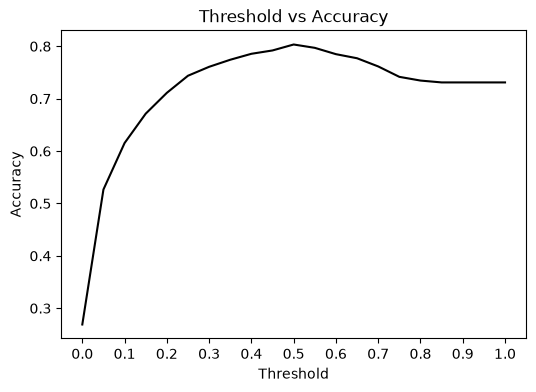

In [60]:
plt.figure(figsize=(6,4))
plt.plot(thresholds,accuracies,color ='black')
plt.title("Threshold vs Accuracy")
plt.xlabel("Threshold")
plt.ylabel('Accuracy')
plt.xticks(np.linspace(0,1,11))
plt.show();

### **Confusion table**

In [61]:
tp = ((y_pred >= 0.5) & (y_val == 1)).sum()
fp = ((y_pred >= 0.5) & (y_val == 0)).sum()
tn = ((y_pred < 0.5) & (y_val == 1)).sum()
fn = ((y_pred < 0.5) & (y_val == 0)).sum()

In [62]:
confusion_matrix = np.array([[tn,fp],
                            [fn,tp]])
confusion_matrix

array([[174, 103],
       [927, 205]])

Precision and recall

In [63]:
precision = tp /(tp+fp)
recall = tp /(tp+fn)
precision,recall

(np.float64(0.6655844155844156), np.float64(0.18109540636042404))

ROC and AUC

In [64]:
scores = []
thresholds = np.linspace(0,1,101)
for t in thresholds:
    tp = ((y_pred >= t) & (y_val == 1)).sum()
    fp = ((y_pred >= t) & (y_val == 0)).sum()
    tn = ((y_pred < t) & (y_val == 1)).sum()
    fn = ((y_pred < t) & (y_val == 0)).sum()
    scores.append((t,tp,fp,tn,fn))
df_scores = pd.DataFrame(scores)
df_scores.columns = ['threshold', 'tp', 'fp', 'fn', 'tn']

In [65]:
df_scores[::10]

,threshold,tp,fp,fn,tn
0,0.0,379,1030,0,0
10,0.1,354,517,25,513
20,0.2,319,347,60,683
30,0.3,285,243,94,787
40,0.4,247,170,132,860
50,0.5,205,103,174,927
60,0.6,139,63,240,967
70,0.7,60,17,319,1013
80,0.8,5,0,374,1030
90,0.9,0,0,379,1030


In [66]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

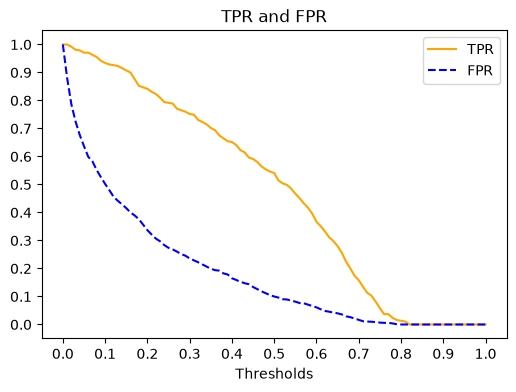

In [67]:
plt.figure(figsize=(6,4))
plt.plot(df_scores.threshold,df_scores.tpr,color='orange',linestyle='solid',label='TPR')
plt.plot(df_scores.threshold,df_scores.fpr,color='blue',linestyle='dashed',label='FPR')
plt.legend()
plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))
plt.xlabel("Thresholds")
plt.title("TPR and FPR")
plt.show();

In [68]:
def tpr_fpr_dataframe(y_val,y_pred):
    scores = []
    thresholds = np.linspace(0,1,101)

    for t in thresholds:
        tp = ((y_pred >= t) & (y_val == 1)).sum()
        fp = ((y_pred >= t) & (y_val == 0)).sum()
        tn = ((y_pred < t) & (y_val == 1)).sum()
        fn = ((y_pred < t) & (y_val == 0)).sum()
        scores.append((t,tp,fp,tn,fn))

    df_scores = pd.DataFrame(scores)
    df_scores.columns = ['threshold', 'tp', 'fp', 'fn', 'tn']

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores


In [69]:
np.random.seed(42)
y_rand = np.random.uniform(0,1,size=len(y_val))
df_rand = tpr_fpr_dataframe(y_val,y_rand)
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,379,1030,0,0,1.000000,1.000000
10,0.1,335,923,44,107,0.883905,0.896117
20,0.2,290,813,89,217,0.765172,0.789320
30,0.3,256,710,123,320,0.675462,0.689320
40,0.4,222,611,157,419,0.585752,0.593204
50,0.5,192,519,187,511,0.506596,0.503883
60,0.6,157,414,222,616,0.414248,0.401942
70,0.7,116,308,263,722,0.306069,0.299029
80,0.8,82,209,297,821,0.216359,0.202913
90,0.9,44,99,335,931,0.116095,0.096117


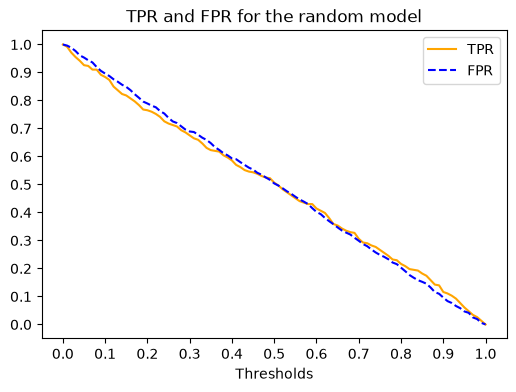

In [70]:
plt.figure(figsize=(6,4))
plt.plot(df_rand.threshold,df_rand.tpr,color='orange',linestyle='solid',label='TPR')
plt.plot(df_rand.threshold,df_rand.fpr,color='blue',linestyle='dashed',label='FPR')
plt.legend()

plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))

plt.xlabel('Thresholds')
plt.title("TPR and FPR for the random model")
plt.show();

In [72]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer

In [73]:
def train(df,y,C=1.0):
    cat = df[categorical+numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear',C=C)
    model.fit(X,y)
    return dv,model

def predict(df,dv,model):
    cat = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(cat)
    y_pred = model.predict_proba(X)[:,1]
    return y_pred


In [75]:
df_test.head(2)

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,1024-guald,female,0,yes,no,1,no,no_phone_service,dsl,no,no,no,no,no,no,month-to-month,yes,electronic_check,24.80,24.80
1,0484-jpbru,male,0,no,no,41,yes,yes,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,yes,bank_transfer_(automatic),25.25,996.45


In [76]:
y_train = df_full_train.churn.values
# y_test = df_test.churn.values

dv,model = train(df_full_train,y_train,C=0.5)
y_pred = predict(df_test,dv,model)

auc = roc_auc_score(y_test,y_pred)
print(f'AUC : {auc:.3f}')

AUC : 0.861


In [77]:
import joblib

In [78]:
joblib.dump((dv, model), 'churn-model.bin')

['churn-model.bin']

In [ ]:
def predict_single(customer, dv, model):
    X = dv.transform([customer])
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred[0]

: 

In [ ]:
customer = {
    'customerid': '8879-zkjof',
    'gender': 'female',
    'seniorcitizen': 0,
    'partner': 'no',
    'dependents': 'no',
    'tenure': 41,
    'phoneservice': 'yes',
    'multiplelines': 'no',
    'internetservice': 'dsl',
    'onlinesecurity': 'yes',
    'onlinebackup': 'no',
    'deviceprotection': 'yes',
    'techsupport': 'yes',
    'streamingtv': 'yes',
    'streamingmovies': 'yes',
    'contract': 'one_year',
    'paperlessbilling': 'yes',
    'paymentmethod': 'bank_transfer_(automatic)',
    'monthlycharges': 79.85,
    'totalcharges': 3320.75
}

In [ ]:
import requests
url = 'http://127.0.0.1:9696/predict'
response = requests.post(url,json=customer)
result = response.json()
result

{'churn_probability': 0.058995567702756484, 'churn': False}